In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
arima = pd.read_csv('../results/metrics/arima_results_filtered.csv')
stgnn = pd.read_csv('../results/metrics/gnn_results.csv')
lstm = pd.read_csv('../results/metrics/lstm_store_results.csv')
xgboost = pd.read_csv('../results/metrics/xgboost_results.csv')

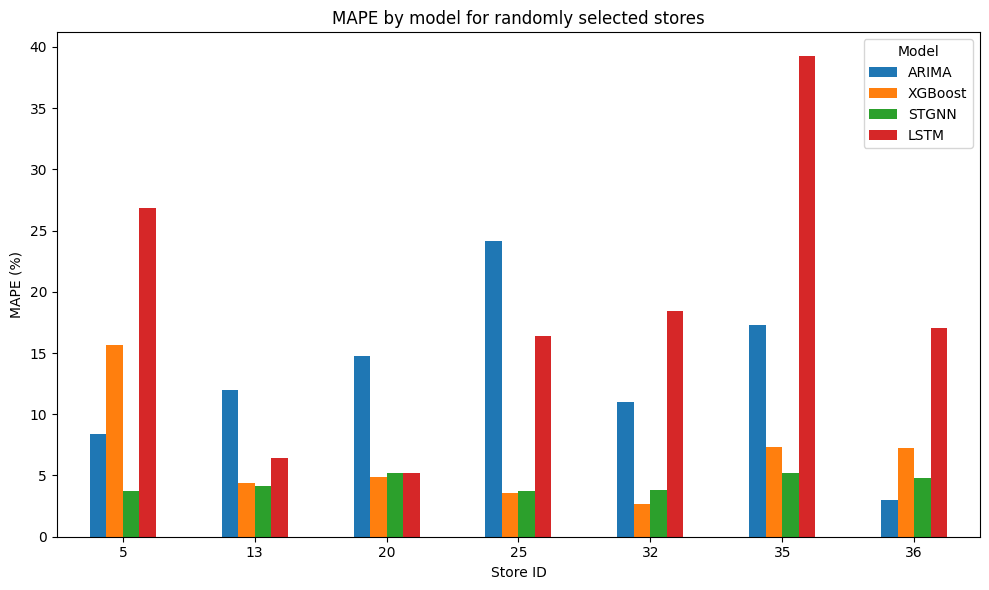

In [19]:
import numpy as np
# replace=False ensures we don't pick the same store twice
random_stores = np.random.choice([i for i in range(1, 46)], size=7, replace=False)
random_stores.sort()

# build a unified MAPE table (ensure we use the existing dataframes)
mape_dict = {
    'ARIMA': arima.set_index('Store ID')['MAPE (%)'].reindex(random_stores),
    'XGBoost': xgboost.set_index('Store ID')['MAPE (%)'].reindex(random_stores),
    'STGNN': stgnn.set_index('Store')['MAPE (%)'].reindex(random_stores),
    'LSTM': lstm.set_index('store')['mape'].reindex(random_stores)
}

mape_df = pd.DataFrame(mape_dict, index=random_stores)

# plot grouped bar chart
ax = mape_df.plot(kind='bar', figsize=(10, 6))
ax.set_xlabel('Store ID')
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE by model for randomly selected stores')
ax.set_xticklabels(mape_df.index, rotation=0)
ax.legend(title='Model')
plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_55632\348307813.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


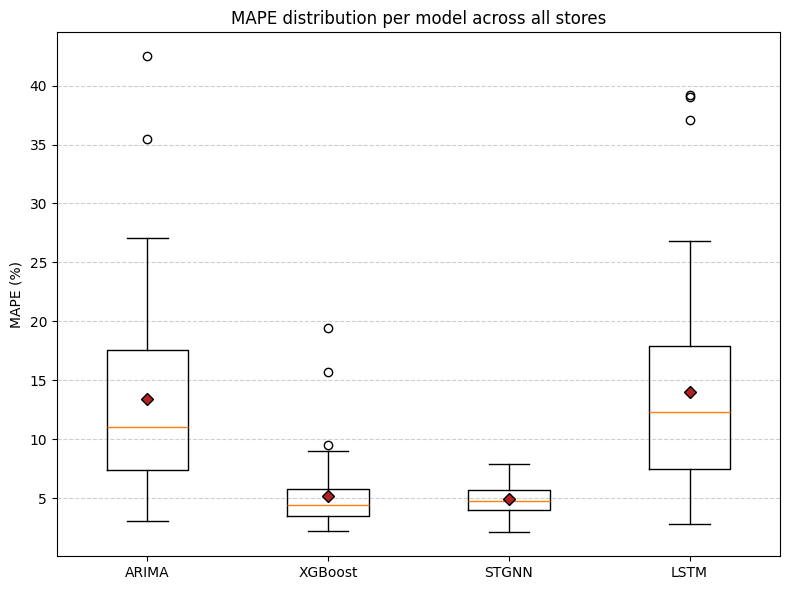

In [12]:
# boxplot of MAPE distribution per model across all stores
mape_data = [
    arima['MAPE (%)'].values,
    xgboost['MAPE (%)'].values,
    stgnn['MAPE (%)'].values,
    lstm['mape'].values
]

plt.figure(figsize=(8, 6))
plt.boxplot(
    mape_data,
    labels=['ARIMA', 'XGBoost', 'STGNN', 'LSTM'],
    showmeans=True,
    meanprops=dict(marker='D', markeredgecolor='black', markerfacecolor='firebrick')
)
plt.ylabel('MAPE (%)')
plt.title('MAPE distribution per model across all stores')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

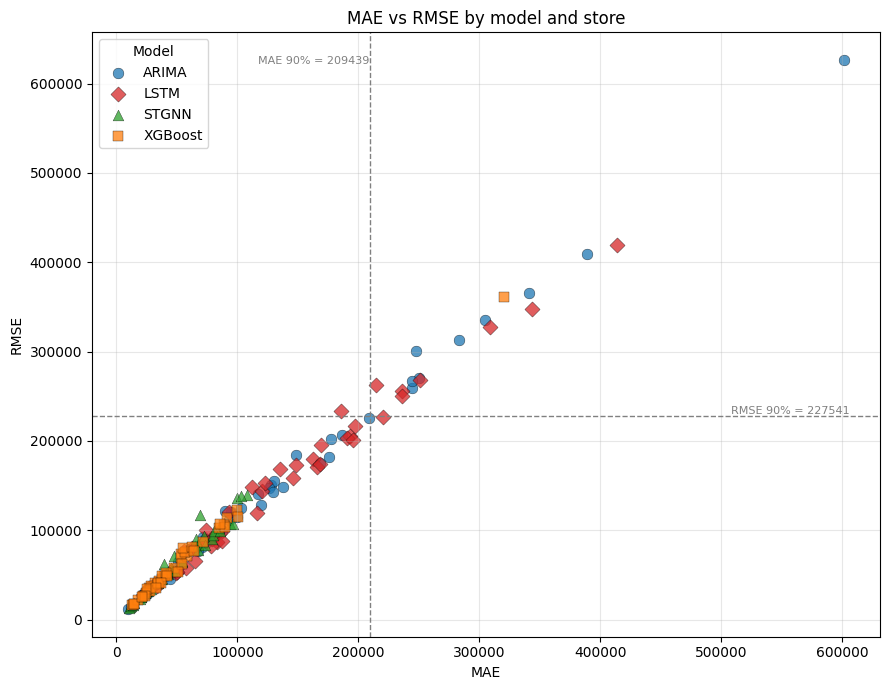

In [13]:
# scatter plot: MAE vs RMSE for all models and stores
arima_plot = arima[['Store ID', 'MAE', 'RMSE']].rename(columns={'Store ID': 'store'})
arima_plot['model'] = 'ARIMA'

xgb_plot = xgboost[['Store ID', 'MAE', 'RMSE']].rename(columns={'Store ID': 'store'})
xgb_plot['model'] = 'XGBoost'

stg_plot = stgnn[['Store', 'MAE ($)', 'RMSE ($)']].rename(columns={'Store': 'store', 'MAE ($)': 'MAE', 'RMSE ($)': 'RMSE'})
stg_plot['model'] = 'STGNN'

lstm_plot = lstm[['store', 'mae', 'rmse']].rename(columns={'mae': 'MAE', 'rmse': 'RMSE'})
lstm_plot['model'] = 'LSTM'

combined = pd.concat([arima_plot, xgb_plot, stg_plot, lstm_plot], ignore_index=True)

fig, ax = plt.subplots(figsize=(9, 7))
markers = {'ARIMA': 'o', 'XGBoost': 's', 'STGNN': '^', 'LSTM': 'D'}
colors = {'ARIMA': 'C0', 'XGBoost': 'C1', 'STGNN': 'C2', 'LSTM': 'C3'}

for model, grp in combined.groupby('model'):
    ax.scatter(grp['MAE'], grp['RMSE'],
               label=model, alpha=0.75, s=60,
               marker=markers[model], color=colors[model], edgecolor='k', linewidth=0.3)

# 90th percentile thresholds to highlight large-error region
mae_th = combined['MAE'].quantile(0.90)
rmse_th = combined['RMSE'].quantile(0.90)
ax.axvline(mae_th, color='gray', linestyle='--', linewidth=1)
ax.axhline(rmse_th, color='gray', linestyle='--', linewidth=1)
ax.text(mae_th, ax.get_ylim()[1]*0.96, f'MAE 90% = {mae_th:.0f}', ha='right', va='top', fontsize=8, color='gray')
ax.text(ax.get_xlim()[1]*0.96, rmse_th, f'RMSE 90% = {rmse_th:.0f}', ha='right', va='bottom', fontsize=8, color='gray')

ax.set_xlabel('MAE')
ax.set_ylabel('RMSE')
ax.set_title('MAE vs RMSE by model and store')
ax.legend(title='Model')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()